<a href="https://colab.research.google.com/github/AW2500100221/Data-Science-Project/blob/main/Heat_levels_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import files
import io
import pandas as pd

# Prompt to upload file
uploaded = files.upload()

# Retrieve the file name
file_name = list(uploaded.keys())[0]
print(f'Successfully uploaded: {file_name}')

KeyboardInterrupt: 

In [5]:
#Weather Temperature Prediction
#Predicting Climate Change
#Process
#Step 1: Finding a database of weather conditions. I found a dataset of Indian daily weather from 2014 to 2024.
#Step 2: Choosing an area of focus. As my main goal is to predict the weather or temperature, I picked heat level as my main focus.
#Step 3: Import the CSV file.
#Step 4: Write a program that will project a graph of the heat levels and predict the future points after getting input in years from the user.

Enter number of years to forecast: 0


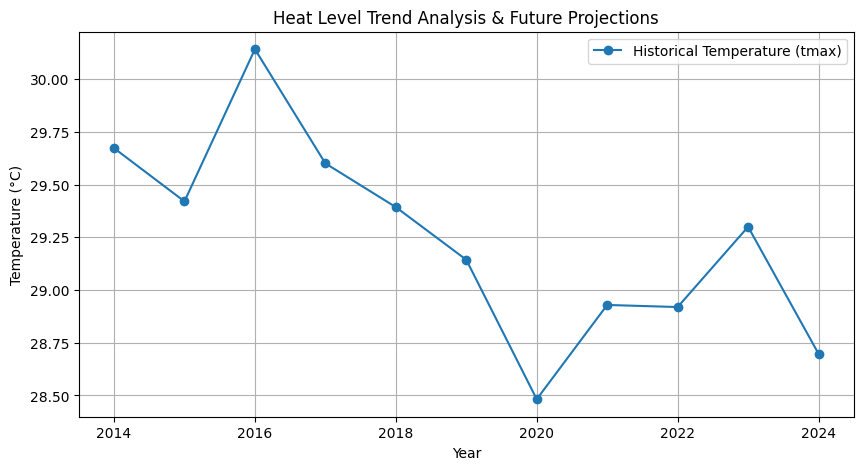

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Safely load the correctly uploaded file name
try:
    df = pd.read_csv(file_name)
except NameError:
    df = pd.read_csv("final_dataset.csv")

# Convert date column to datetime and extract the Year
df["date"] = pd.to_datetime(df["date"])
df["Year"] = df["date"].dt.year

# Aggregate temperature (tmax) by Year to find the annual trend
annual_data = df.groupby("Year")["tmax"].mean().reset_index()

# Get user input
years_to_forecast = int(input("Enter number of years to forecast: "))

# Calculate the historical heat trend line on annual averages
slope, intercept = np.polyfit(annual_data["Year"], annual_data["tmax"], 1)

# Generate future years and project the temperature increase
last_year = annual_data["Year"].iloc[-1]
future_years = np.arange(last_year + 1, last_year + 1 + years_to_forecast)
future_temps = slope * future_years + intercept

# Plot historical data and the extended trend line
plt.figure(figsize=(10, 5))
plt.plot(annual_data["Year"], annual_data["tmax"], label="Historical Temperature (tmax)", marker="o")
if years_to_forecast > 0:
    plt.plot(
        future_years,
        future_temps,
        label="Projected Heat Increase",
        color="red",
        linestyle="--",
        marker="x",
    )

# Formatting the graph
plt.title("Heat Level Trend Analysis & Future Projections")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)

# Display the chart
plt.show()